<a href="https://colab.research.google.com/github/soyeonkm/datasci101/blob/main/module3_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module Project 3: Cancer Death Rates

The federal government’s **Healthy People 2030** plan sets a national
target for cancer: by 2030, no more than **122.7 cancer deaths per
100,000 people per year**. In 2018, the plan’s baseline year, the US
rate was 149.1. Every rate in this project is **age-adjusted**: it is
the rate a place would have if its residents had the same mix of ages as
the US population in 2000. Older people die of cancer far more often
than younger people, so without the adjustment a county full of retirees
would always look worse than a college town.

This project uses two tables. The first follows the national rate year
by year since 1900. The second gives the rate for nearly every US county
in 2020 to 2024. Because every county’s rate is published, the county
table lets you check this module’s tools against the truth. You will
draw samples of counties, run tests and build confidence intervals from
them, and then compare what they say with the answer computed from all
of the counties.

Part 1 loads the tables and asks what population they describe and which
counties are missing. Part 2 tests hypotheses from one sample of
counties. Part 3 builds confidence intervals and checks how often they
contain the truth. Part 4 repeats the work with the functions in
`scipy.stats` and adds the $t$ and $\chi^2$ tests. Part 5 asks when the
methods can be trusted. **Each part uses one plenary session, in
order**, so you can develop your project over the course of the module.

**Display every result a question asks for.** You will work later from a
printed copy of this notebook, so a result that is not displayed will
not be on the page. Put the value on the last line of the cell so it
prints. When a question asks for several values and gives you one cell,
put them in a dictionary and make that the last line, as in
`{"rows": counties.shape[0], "columns": counties.shape[1]}`, so every
value prints with a label.

Most questions are followed by a **check cell** of commented-out
`assert` lines you can use to test your work; the cell itself tells you
how. A check that passes says your result has the right value. A check
that fails names the line that failed.

Each question starts with a motivating question. Do not answer it right
away. Work through the steps, which give you what you need to answer it.
On the quiz you will be asked what you found and how it answers the
motivating questions.

Several questions draw random samples. Each of those parts has a **seed
cell** above the sampling code. Run the seed cell first, then the cells
below it, so your numbers match your classmates’ notebooks. To run a
sampling cell again, run its seed cell again first.

### The data

Both tables come from US government sources and are in the public
domain.

**`counties`** comes from [State Cancer
Profiles](https://statecancerprofiles.cancer.gov/), run by the National
Cancer Institute and the CDC. Each **row is one county** in the 50
states or DC, and each rate covers all cancer sites for the five years
2020 to 2024. The national rate for the same years is **143.2**.

| Column | Meaning |
|------------------------------------|------------------------------------|
| `county`, `state`, `fips` | County name, state and county code |
| `rural_urban` | `Rural` or `Urban`, from the US Department of Agriculture’s 2023 codes |
| `death_rate` | Age-adjusted cancer deaths per 100,000 people per year |
| `rate_lower`, `rate_upper` | A 95% confidence interval for `death_rate` |
| `met_objective` | `Yes` if `death_rate` is at most 122.7 |
| `annual_deaths` | Average number of cancer deaths per year |
| `aapc` | Recent five-year trend: the average annual percent change in the death rate |
| `aapc_lower`, `aapc_upper` | A 95% confidence interval for `aapc` |
| `trend` | `falling`, `stable` or `rising`, from the interval for `aapc` |

A county with fewer than 16 cancer deaths in the five years has its rate
**suppressed**, to protect privacy and because a rate from so few deaths
is unstable. Suppressed values are missing.

**`us`** comes from the National Center for Health Statistics. It has
one row per year from 1900 to 2018, with the US age-adjusted cancer
death rate in `death_rate`.

# Part 1: Where the data come from (Plenary 3.1)

In [137]:
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
from scipy import stats

The data live at these addresses. Loading from the URL means you never
need to manage a file.

In [138]:
counties_url = "https://github.com/UM-Data-Science-101/data/raw/refs/heads/main/Cancer%20Death%20Rates/cancer_deaths_by_county.csv"
us_url = "https://github.com/UM-Data-Science-101/data/raw/refs/heads/main/Cancer%20Death%20Rates/cancer_deaths_us_by_year.csv"

## Question 1: Loading

> **Motivation.** How many counties and how many years do the two tables
> cover?

Read the county data into a table called **`counties`** and the national
data into a table called **`us`**. Display the shape of each in one
dictionary.

*Hint: the plenary 3.1 slides “Loading the homes data” and “Loading the
pulsar data” load tables from a URL.*

In [139]:
# your code here
counties = pd.read_csv(counties_url)
us = pd.read_csv(us_url)

{
    "counties": counties.shape,
    "us": us.shape
}

{'counties': (3142, 13), 'us': (119, 2)}

In [140]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert counties.shape == (3142, 13)
assert us.shape == (119, 2)
assert "death_rate" in counties.columns and "death_rate" in us.columns

## Question 2: Five questions

> **Motivation.** Which counties have no death rate, and what else
> should you know about how this table came to be before you draw
> conclusions from it?

### (a) Missing counties

Display three values in one dictionary: the number of counties with a
missing `death_rate`, the proportion of those counties that are `Rural`,
and the proportion of all counties that are `Rural`.

Then make a table **`rated`** that holds only the counties with a
`death_rate`, and display its number of rows. From here on, the
**population** is the counties in `rated`.

*Hint: Module 2 found missing values with `isna`.*

In [141]:
# your code here
missing = counties[counties["death_rate"].isna()]

{
    "missing death_rate": missing.shape[0],
    "proportion missing that are Rural": (missing["rural_urban"] == "Rural").mean(),
    "proportion all counties that are Rural": (counties["rural_urban"] == "Rural").mean()
}

{'missing death_rate': 58,
 'proportion missing that are Rural': np.float64(0.9655172413793104),
 'proportion all counties that are Rural': np.float64(0.622533418204965)}

In [142]:
# your code here
rated = counties[counties["death_rate"].notna()]

rated.shape[0]

3084

In [143]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert rated.shape == (3084, 13)
assert rated["death_rate"].notna().all()

### (b) The five questions

Plenary 3.1 asks five questions of any data set. Answer them for the
county table by making a dictionary **`five_questions`** with the keys
`"population"`, `"how chosen"`, `"missing"`, `"when"` and `"groups"`.
Each value is **one of the choices listed below, copied exactly** as a
string. The check cell tests your answers without showing them.

- `"population"`, who we want conclusions about:
  - `"every US resident"`
  - `"every US county"`
  - `"the 50 counties with the most cancer deaths"`
  - `"counties with a falling trend"`
- `"how chosen"`, how counties got into the table:
  - `"a simple random sample of counties"`
  - `"counties that volunteered to report"`
  - `"every county is listed; none was sampled"`
  - `"counties chosen by the National Cancer Institute"`
- `"missing"`, who has no rate:
  - `"large urban counties"`
  - `"counties with rising rates"`
  - `"no county is missing"`
  - `"small counties with too few deaths to report a rate"`
- `"when"`, the time each rate covers:
  - `"one rate per county for 2020 to 2024 together"`
  - `"one rate per county for each year from 2020 to 2024"`
  - `"a single day in 2024"`
  - `"every year from 1900 to 2018"`
- `"groups"`, how a county came to be `Rural` or `Urban`:
  - `"assigned at random by a researcher"`
  - `"recorded, not assigned: it is a trait of the county"`
  - `"assigned by a researcher to balance the groups"`
  - `"chosen by each county's health department"`

*Hint: plenary 3.1’s slide “Five questions for any data set”, and the
slides that answer them for the homes, pulsar and Back Bay data.*

In [144]:
# your code here
five_questions = {
    "population": "every US county",
    "how chosen": "every county is listed; none was sampled",
    "missing": "small counties with too few deaths to report a rate",
    "when": "one rate per county for 2020 to 2024 together",
    "groups": "recorded, not assigned: it is a trait of the county"
}

five_questions

{'population': 'every US county',
 'how chosen': 'every county is listed; none was sampled',
 'missing': 'small counties with too few deaths to report a rate',
 'when': 'one rate per county for 2020 to 2024 together',
 'groups': 'recorded, not assigned: it is a trait of the county'}

In [145]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
import hashlib
code = lambda answer: hashlib.sha256(answer.strip().lower().encode()).hexdigest()[:10]
assert code(five_questions["population"]) == "55e3721be8"
assert code(five_questions["how chosen"]) == "aacf7fa1a4"
assert code(five_questions["missing"]) == "bd75137f72"
assert code(five_questions["when"]) == "e21fa37d80"
assert code(five_questions["groups"]) == "caaf1a0292"

## Question 3: The population

> **Motivation.** What is the death rate of a typical county, and how
> does it compare with the national rate of 143.2?

### (a) Population values

Compute three population values from `rated`. **`mu`** is the mean of
`death_rate`, **`sigma`** is its standard deviation, from `std`, and
**`N`** is the number of counties. Display the three and the median of
`death_rate` in one dictionary.

In [146]:
# your code here
mu = rated["death_rate"].mean()
sigma = rated["death_rate"].std()
N = rated.shape[0]
median = rated["death_rate"].median()

{
    "mu": mu,
    "sigma": sigma,
    "N": N,
    "median": median
}

{'mu': np.float64(162.43005836575875),
 'sigma': 29.098376673015668,
 'N': 3084,
 'median': 160.8}

In [147]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs(mu - 162.430) < 0.001
assert abs(sigma - 29.098) < 0.001
assert N == 3084

### (b) Rural and urban counties

Display the mean `death_rate` and the mean `annual_deaths` for rural and
for urban counties, as one table with a row for each.

*Hint: Module 2 summarized groups with `groupby` and `agg`.*

In [148]:
# your code here
rated.groupby("rural_urban").agg({
    "death_rate": "mean",
    "annual_deaths": "mean"
})

,death_rate,annual_deaths
rural_urban,,
Rural,166.762158,58.826842
Urban,155.478209,420.579392


## Question 4: A convenience sample

> **Motivation.** A researcher can only get records from the counties
> with the most cancer deaths, which have large health departments. Can
> the mean rate of those counties estimate `mu`?

### (a) The largest counties

Sort `rated` by `annual_deaths` from largest to smallest. Make
**`largest`**, the first 50 rows. For `largest`, and then for the first
200 rows, display the mean `death_rate` and its $z$-score
$z = (\bar x - \mu) / (\sigma / \sqrt{n})$. Also display the proportion
of `largest` that is `Urban`.

*Hint: `sort_values` takes `ascending=False`. Plenary 3.1’s slide “A
survey from a mortgage list” builds a list sample like this one.*

In [149]:
# your code here
sorted_rated = rated.sort_values("annual_deaths", ascending=False)

largest = sorted_rated.head(50)
largest_200 = sorted_rated.head(200)

mean_50 = largest["death_rate"].mean()
z_50 = (mean_50 - mu) / (sigma / np.sqrt(50))

mean_200 = largest_200["death_rate"].mean()
z_200 = (mean_200 - mu) / (sigma / np.sqrt(200))

urban_prop = (largest["rural_urban"] == "Urban").mean()

{
    "mean_50": mean_50,
    "z_50": z_50,
    "mean_200": mean_200,
    "z_200": z_200,
    "urban_proportion_50": urban_prop
}

{'mean_50': np.float64(134.34600000000003),
 'z_50': np.float64(-6.824582806394991),
 'mean_200': np.float64(138.1485),
 'z_200': np.float64(-11.801108200051036),
 'urban_proportion_50': np.float64(1.0)}

In [150]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert largest.shape == (50, 13)
assert largest["annual_deaths"].min() >= rated["annual_deaths"].quantile(0.95)
assert abs(largest["death_rate"].mean() - 134.346) < 0.001

### (b) Random samples

Write a function **`simulate_means(n, reps)`** that returns a Series of
`reps` sample means of `death_rate`, each from a new simple random
sample of `n` counties in `rated`.

Run the seed cell, then use `simulate_means` to draw 1,000 sample means
for $n = 50$ and 1,000 for $n = 200$. For each $n$, display the
proportion of sample means within 2 SEMs of `mu`, where the SEM is
$\sigma / \sqrt{n}$.

*Hint: plenary 3.1’s slide “How often within 2 SEMs of the population
mean?” does this for the mortgage-list survey. Module 2’s Question 10
wrote a function like `simulate_means`.*

In [151]:
np.random.seed(301)

In [152]:
# your code here
def simulate_means(n, reps):
    means = []

    for _ in range(reps):
        sample = rated.sample(n=n)
        means.append(sample["death_rate"].mean())

    return pd.Series(means)

means_50 = simulate_means(50, 1000)
means_200 = simulate_means(200, 1000)

sem_50 = sigma / np.sqrt(50)
sem_200 = sigma / np.sqrt(200)

prop_50 = ((means_50 >= mu - 2 * sem_50) &
           (means_50 <= mu + 2 * sem_50)).mean()

prop_200 = ((means_200 >= mu - 2 * sem_200) &
            (means_200 <= mu + 2 * sem_200)).mean()

{
    "n=50": prop_50,
    "n=200": prop_200
}

{'n=50': np.float64(0.953), 'n=200': np.float64(0.955)}

In [153]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert type(simulate_means(5, 10)) == pd.Series
assert len(simulate_means(5, 10)) == 10
assert simulate_means(1, 20).isin(rated["death_rate"]).all()

## Question 5: The national rate over time

> **Motivation.** Has the national cancer death rate been falling, and
> is it falling fast enough to reach 122.7 by 2030?

### (a) The whole series

Plot `death_rate` against `year` for every row of `us` as a line plot.

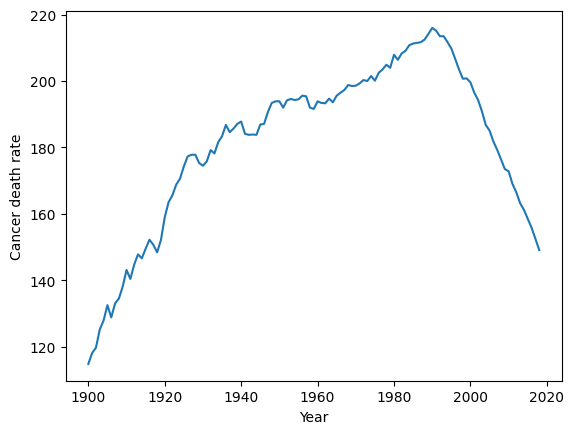

In [154]:
# your code here
plt.plot(us["year"], us["death_rate"])
plt.xlabel("Year")
plt.ylabel("Cancer death rate")
plt.show()

### (b) Yearly changes since 1999

In 1999 the US began coding causes of death with a new revision of the
International Classification of Diseases, so rates before 1999 may not
be directly comparable with later ones. Make **`recent`**, the rows of
`us` from 1999 on. Then make **`changes`**, the change in the rate from
each year to the next. The `diff` method subtracts from each value the
value before it. The first value has nothing before it and comes out
missing, so drop it.

Display the number of changes, their mean and their standard deviation,
and the yearly change needed to go from 149.1 in 2018 to 122.7 in 2030,
all in one dictionary.

*Hint: the “When?” item on plenary 3.1’s slide “Five questions for any
data set”.*

In [155]:
# your code here
recent = us[us["year"] >= 1999]

changes = recent["death_rate"].diff().dropna()

needed_change = (122.7 - 149.1) / (2030 - 2018)

{
    "number of changes": len(changes),
    "mean change": changes.mean(),
    "standard deviation": changes.std(),
    "needed yearly change": needed_change
}

{'number of changes': 19,
 'mean change': np.float64(-2.721052631578948),
 'standard deviation': 0.8670377073489436,
 'needed yearly change': -2.1999999999999993}

In [156]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert len(changes) == 19
assert abs(changes.mean() - (-2.721)) < 0.001

# Part 2: Hypothesis tests (Plenary 3.2)

In practice a researcher would not have every county’s rate. From here
on you work from **one random sample of 50 counties**, the way you would
if you could only collect 50, and use `mu` and the other population
values only to check the results. In the plenary’s notation, `mu` is
$E(X)$, where $X$ is the `death_rate` of a county drawn at random from
`rated`.

The tests in this part are two-tailed. Following plenary 3.2, reject the
null hypothesis when the sample mean is more than 2 SEMs from the null
value, that is when $|z| > 2$.

## Question 6: One sample

> **Motivation.** What does one sample of 50 counties say about the
> typical county’s death rate?

Run the seed cell. Then draw **`sample50`**, a simple random sample of
50 rows of `rated`, using `sample`. Display the sample size, the sample
mean and standard deviation of `death_rate`, and the estimated SEM,
$s / \sqrt{n}$, in one dictionary.

*Hint: plenary 3.2’s slide “Estimating the SEM” estimates the SEM from
the sample.*

In [157]:
np.random.seed(302)

In [158]:
# your code here
sample50 = rated.sample(n=50)

n = sample50.shape[0]
sample_mean = sample50["death_rate"].mean()
sample_sd = sample50["death_rate"].std()
estimated_sem = sample_sd / np.sqrt(n)

{
    "sample size": n,
    "sample mean": sample_mean,
    "sample standard deviation": sample_sd,
    "estimated SEM": estimated_sem
}

{'sample size': 50,
 'sample mean': np.float64(167.82),
 'sample standard deviation': 29.79504136254754,
 'estimated SEM': np.float64(4.213655158638207)}

In [159]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert sample50.shape == (50, 13)
assert sample50["death_rate"].isin(rated["death_rate"]).all()
assert abs(sample50["death_rate"].mean() - 167.82) < 0.001

## Question 7: A z-test

> **Motivation.** Is the typical county’s death rate the national rate
> of 143.2? A news story claims the typical county’s rate is 160. Does
> the sample support that?

Write a function **`z_test(x, mu0)`** that takes a Series of values and
a null value $\mu_0$ and returns a dictionary with four entries:
`"mean"`, the sample mean; `"sem"`, the estimated SEM; `"z"`,
$(\bar x - \mu_0) / \text{SEM}$; and `"p-value"`, the two-tailed p-value
$2 \, P(Z \le -|z|)$.

Test $H_0: \mu = 143.2$ and $H_0: \mu = 160$ on the `death_rate` column
of `sample50`. Display both results as one table, using
`pd.DataFrame({"143.2": ..., "160": ...})`.

*Hint: plenary 3.2’s slides “Running the two-tailed test”, “Computing
p-values” and “P-values for the pulsar tests”. `stats.norm.cdf(z)` is
$P(Z \le z)$ and `abs` gives an absolute value.*

In [160]:
# your code here
def z_test(x, mu0):
    mean = x.mean()
    sem = x.std() / np.sqrt(len(x))
    z = (mean - mu0) / sem
    p_value = 2 * stats.norm.cdf(-abs(z))

    return {
        "mean": mean,
        "sem": sem,
        "z": z,
        "p-value": p_value
    }

results = pd.DataFrame({
    "143.2": z_test(sample50["death_rate"], 143.2),
    "160": z_test(sample50["death_rate"], 160)
})

results

,143.2,160
mean,1.678200e+02,167.820000
sem,4.213655e+00,4.213655
z,5.842908e+00,1.855871
p-value,5.129731e-09,0.063472


In [161]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
check = z_test(pd.Series([1, 2, 3, 4, 5]), 2)
assert set(check.keys()) == {"mean", "sem", "z", "p-value"}
assert abs(check["sem"] - 0.7071) < 0.0001
assert abs(check["z"] - 1.4142) < 0.0001
assert abs(check["p-value"] - 0.1573) < 0.0001
assert abs(z_test(pd.Series([1, 2, 3, 4, 5]), 4)["z"] + 1.4142) < 0.0001

## Question 8: A test for a proportion

> **Motivation.** Is the cancer death rate falling in most counties?

Let $p$ be the proportion of counties in `rated` whose `trend` is
`"falling"`. Counties with no trend count as not falling. We test
$H_0: p = 0.5$ against $H_1: p \ne 0.5$.

Write a function **`prop_test(x, p0)`** that takes a boolean Series and
a null value $p_0$ and returns a dictionary with four entries:
`"p hat"`, the sample proportion; `"se"`, the standard error under the
null hypothesis, $\sqrt{p_0 (1 - p_0) / n}$; `"z"`,
$(\hat p - p_0) / \text{SE}$; and `"p-value"`, the two-tailed p-value.
Apply it to whether each county in `sample50` has a falling trend.

*Hint: plenary 3.2’s slide “Proportions” gives the standard error from
$p_0$.*

In [162]:
# your code here
def prop_test(x, p0):
    p_hat = x.mean()
    n = len(x)

    se = np.sqrt(p0 * (1 - p0) / n)
    z = (p_hat - p0) / se
    p_value = 2 * stats.norm.cdf(-abs(z))

    return {
        "p hat": p_hat,
        "se": se,
        "z": z,
        "p-value": p_value
    }

prop_test(sample50["trend"] == "falling", 0.5)

{'p hat': np.float64(0.52),
 'se': np.float64(0.07071067811865475),
 'z': np.float64(0.2828427124746193),
 'p-value': np.float64(0.7772974107895213)}

In [163]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
check = prop_test(pd.Series([True] * 30 + [False] * 70), 0.5)
assert abs(check["p hat"] - 0.3) < 0.0001
assert abs(check["se"] - 0.05) < 0.0001
assert abs(check["z"] + 4) < 0.0001

## Question 9: Checking against the truth

> **Motivation.** Which of the three tests reached the right decision?

Build a table **`decisions`** with one row for each test in Questions 7
and 8, indexed by `"mean = 143.2"`, `"mean = 160"` and
`"falling = 0.5"`. Give it four columns: `"null value"`; `"true value"`,
which is `mu` for the two mean tests and the proportion of `rated` with
a falling trend for the third; `"reject"`, whether $|z| > 2$; and
`"null true"`, whether the null value equals the true value. Display the
table.

*Hint: plenary 3.2’s slide “Four possible outcomes” pairs the decision
with the truth.*

In [164]:
# your code here
falling_true = (rated["trend"] == "falling").mean()

test_143 = z_test(sample50["death_rate"], 143.2)
test_160 = z_test(sample50["death_rate"], 160)
test_falling = prop_test(sample50["trend"] == "falling", 0.5)

decisions = pd.DataFrame(
    {
        "null value": [143.2, 160, 0.5],
        "true value": [mu, mu, falling_true],
        "reject": [
            abs(test_143["z"]) > 2,
            abs(test_160["z"]) > 2,
            abs(test_falling["z"]) > 2
        ],
        "null true": [
            143.2 == mu,
            160 == mu,
            0.5 == falling_true
        ]
    },
    index=["mean = 143.2", "mean = 160", "falling = 0.5"]
)

decisions

,null value,true value,reject,null true
mean = 143.2,143.2,162.430058,True,False
mean = 160,160.0,162.430058,False,False
falling = 0.5,0.5,0.520752,False,False


In [165]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert list(decisions.columns) == ["null value", "true value", "reject", "null true"]
assert list(decisions.index) == ["mean = 143.2", "mean = 160", "falling = 0.5"]
assert abs(decisions.loc["falling = 0.5", "true value"] - 0.5208) < 0.0001

## Question 10: How often tests make errors

> **Motivation.** Was the Type II error in Question 9 bad luck, or
> should it be expected?

Write a function **`rejection_rate(mu0, n, reps)`** that draws `reps`
simple random samples of `n` counties from `rated`, runs `z_test` on
each sample’s `death_rate` with null value `mu0`, and returns the
proportion of samples with $|z| > 2$.

Run the seed cell, then display the rejection rate for 1,000 samples of
50 with each of these null values, in one dictionary: `mu` (a true
null), 160 and 143.2.

*Hint: plenary 3.2’s slide “Four possible outcomes”.*

In [166]:
np.random.seed(303)

In [167]:
# your code here
def rejection_rate(mu0, n, reps):
    rejects = []

    for _ in range(reps):
        sample = rated.sample(n=n)
        result = z_test(sample["death_rate"], mu0)
        rejects.append(abs(result["z"]) > 2)

    return np.mean(rejects)

np.random.seed(303)

{
    "mu": rejection_rate(mu, 50, 1000),
    "160": rejection_rate(160, 50, 1000),
    "143.2": rejection_rate(143.2, 50, 1000)
}

{'mu': np.float64(0.039), '160': np.float64(0.076), '143.2': np.float64(0.998)}

In [168]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert 0 <= rejection_rate(mu, 10, 20) <= 1
assert rejection_rate(0, 10, 20) == 1

# Part 3: Confidence intervals (Plenary 3.3)

## Question 11: A confidence interval for the mean

> **Motivation.** Instead of testing one value at a time, which values
> of the typical county’s rate does the sample support?

Write a function **`z_interval(x, a)`** that takes a Series and a number
of SEMs $a$ and returns a tuple `(lower, upper)`, the interval
$\bar x \pm a \cdot \text{SEM}$. As in plenary 3.3, $a = 2$ gives a 95%
interval and $a = 3$ a 99.7% interval.

For `sample50`’s `death_rate`, display in one dictionary the 95% and
99.7% intervals and whether each contains `mu`. Also display whether
143.2 and 160 are inside the 95% interval.

*Hint: plenary 3.3’s slides “Set of not-rejected null hypotheses”, “CI
for $E(X)$” and “A more stringent Type I error rate”.*

In [169]:
# your code here
def z_interval(x, a):
    mean = x.mean()
    sem = x.std() / np.sqrt(len(x))

    lower = mean - a * sem
    upper = mean + a * sem

    return (lower, upper)

ci_95 = z_interval(sample50["death_rate"], 2)
ci_997 = z_interval(sample50["death_rate"], 3)

{
    "95% interval": ci_95,
    "95% contains mu": ci_95[0] <= mu <= ci_95[1],
    "99.7% interval": ci_997,
    "99.7% contains mu": ci_997[0] <= mu <= ci_997[1],
    "143.2 in 95%": ci_95[0] <= 143.2 <= ci_95[1],
    "160 in 95%": ci_95[0] <= 160 <= ci_95[1]
}

{'95% interval': (np.float64(159.39268968272359),
  np.float64(176.2473103172764)),
 '95% contains mu': np.True_,
 '99.7% interval': (np.float64(155.17903452408538),
  np.float64(180.4609654759146)),
 '99.7% contains mu': np.True_,
 '143.2 in 95%': np.False_,
 '160 in 95%': np.True_}

In [170]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
lo, hi = z_interval(pd.Series([1, 2, 3, 4, 5]), 2)
assert abs(lo - 1.5858) < 0.0001 and abs(hi - 4.4142) < 0.0001
assert abs(ci_95[0] - 159.393) < 0.001 and abs(ci_95[1] - 176.247) < 0.001

## Question 12: Coverage

> **Motivation.** A 95% interval either contains `mu` or it does not.
> What does the 95% describe?

Write a function **`covers(n, a)`** that draws one simple random sample
of `n` counties from `rated` and returns whether the `z_interval` of its
`death_rate` with `a` SEMs contains `mu`.

Run the seed cell. Then call `covers` 1,000 times with $n = 50$ and
$a = 2$, and 1,000 times with $n = 50$ and $a = 1$, and display the
proportion of each kind of interval that contains `mu`.

*Hint: plenary 3.3’s slides “Simulating CI Coverage” and “Simulation
Continued” write a function that returns whether one interval covers.*

In [171]:
np.random.seed(304)

In [172]:
# your code here

def covers(n, a):
    sample = rated.sample(n=n)
    lo, hi = z_interval(sample["death_rate"], a)
    return lo <= mu <= hi

np.random.seed(304)

coverage_2 = np.mean([covers(50, 2) for _ in range(1000)])
coverage_1 = np.mean([covers(50, 1) for _ in range(1000)])

{
    "a = 2": coverage_2,
    "a = 1": coverage_1
}

{'a = 2': np.float64(0.951), 'a = 1': np.float64(0.654)}

## Question 13: An interval for a proportion

> **Motivation.** Which proportions of falling counties does the sample
> support?

Build a 95% interval for $p$, the proportion of counties with a falling
trend, from `sample50`, as $\hat p \pm 2 \, \text{SE}$ with the
estimated standard error $\sqrt{\hat p (1 - \hat p) / n}$. Do not use
`z_interval` here: it estimates the SE from the standard deviation,
which differs slightly. Display the interval, whether it contains 0.5,
and whether it contains the true proportion `p_true` from Question 9.

*Hint: plenary 3.3’s slide “Example: CI for the share of homes with a
mortgage”.*

In [173]:
# your code here
falling = sample50["trend"] == "falling"

p_hat = falling.mean()
n = len(falling)

se = np.sqrt(p_hat * (1 - p_hat) / n)

ci_p = (
    p_hat - 2 * se,
    p_hat + 2 * se
)

p_true = (rated["trend"] == "falling").mean()

{
    "95% interval": prop_ci,
    "contains 0.5": prop_ci[0] <= 0.5 <= prop_ci[1],
    "contains p_true": prop_ci[0] <= p_true <= prop_ci[1]
}

{'95% interval': (np.float64(0.37869182613875446),
  np.float64(0.6613081738612456)),
 'contains 0.5': np.True_,
 'contains p_true': np.True_}

In [174]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs(ci_p[0] - 0.379) < 0.001 and abs(ci_p[1] - 0.661) < 0.001

## Question 14: The trend labels are intervals

> **Motivation.** What does it mean when State Cancer Profiles calls a
> county’s death rate `stable`, or says a county met the target?

### (a) Rebuilding the labels

The `trend` column is built from the 95% interval for `aapc`: `falling`
when the whole interval is below 0, `rising` when it is above 0, and
`stable` when it contains 0. Make **`trended`**, the rows of `rated`
with a `trend`. Build a Series **`label`** for `trended` from
`aapc_lower` and `aapc_upper` by that rule, and display the proportion
of rows where `label` equals `trend`.

*Hint: plenary 3.3’s slide “Set of not-rejected null hypotheses”. Start
with `label = pd.Series("stable", index=trended.index)`, then use
`label.loc[...] = "falling"` with a boolean condition, and the same for
`rising`.*

In [175]:
# your code here
trended = rated[rated["trend"].notna()]

label = pd.Series("stable", index=trended.index)

label.loc[trended["aapc_upper"] < 0] = "falling"
label.loc[trended["aapc_lower"] > 0] = "rising"

(label == trended["trend"]).mean()

np.float64(1.0)

In [176]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert len(label) == trended.shape[0] == 3062
assert (label == trended["trend"]).all()

### (b) Who is stable

Display the median `annual_deaths` for each `trend` category, and the
number of counties in each.

In [177]:
# your code here
trended.groupby("trend").agg(
    median_annual_deaths=("annual_deaths", "median"),
    count=("annual_deaths", "size")
)

,median_annual_deaths,count
trend,,
falling,125.0,1606
rising,29.0,23
stable,37.0,1433


### (c) Meeting the target

`met_objective` is `Yes` when a county’s `death_rate` is at most 122.7.
Display the number of counties that met the objective, and among them
the number whose 95% interval for the death rate reaches above 122.7 and
the proportion.

In [178]:
# your code here
met = rated[rated["met_objective"] == "Yes"]

above_target = met[met["rate_upper"] > 122.7]

{
    "number met objective": len(met),
    "number CI reaches above 122.7": len(above_target),
    "proportion": len(above_target) / len(met)
}

{'number met objective': 205,
 'number CI reaches above 122.7': 139,
 'proportion': 0.6780487804878049}

## Question 15: The national pace

> **Motivation.** If the national rate keeps falling at its 1999 to 2018
> pace, when will it reach 122.7?

Treat the 19 values in `changes` as a sample of yearly changes. Build a
95% interval for the mean yearly change with `z_interval`. At each end
of the interval, compute two things: the year the rate would reach
122.7, starting from 149.1 in 2018, which is
$2018 + (122.7 - 149.1) / \text{end}$; and the projected 2024 rate,
$149.1 + 6 \times \text{end}$. Display the interval, the two years and
the two projections in one dictionary.

Healthy People reports the actual 2024 rate as **139.4**.

In [179]:
# your code here
ci_change = z_interval(changes, 2)

low = ci_change[0]
high = ci_change[1]

year_low = 2018 + (122.7 - 149.1) / low
year_high = 2018 + (122.7 - 149.1) / high

rate_2024_low = 149.1 + 6 * low
rate_2024_high = 149.1 + 6 * high

{
    "95% interval": ci_change,
    "year from lower end": year_low,
    "year from upper end": year_high,
    "2024 rate from lower end": rate_2024_low,
    "2024 rate from upper end": rate_2024_high
}

{'95% interval': (np.float64(-3.1188768154287625),
  np.float64(-2.3232284477291336)),
 'year from lower end': np.float64(2026.4645856705215),
 'year from upper end': np.float64(2029.363497216903),
 '2024 rate from lower end': np.float64(130.38673910742742),
 '2024 rate from upper end': np.float64(135.16062931362518)}

In [180]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs(ci_change[0] - (-3.119)) < 0.001 and abs(ci_change[1] - (-2.323)) < 0.001

# Part 4: Tests and intervals in software (Plenary 3.4)

## Question 16: The t-test

> **Motivation.** Do the functions in `scipy.stats` agree with your
> `z_test` and `z_interval`?

For `sample50`’s `death_rate`, run `stats.ttest_1samp` against 143.2 and
build a 95% interval with `stats.t.interval`. Display in one dictionary
the $t$ statistic and p-value and the $t$ interval, and for comparison
the `z` and p-value from your `z_test` and your 2-SEM `z_interval`.

*Hint: plenary 3.4’s slides “Test for pulsars’ `profile_mean`” and “CI
for pulsars’ `profile_mean`”. `stats.sem` computes the estimated SEM.*

In [181]:
# your code here
x = sample50["death_rate"]

t_result = stats.ttest_1samp(x, 143.2)

sem = stats.sem(x)
t_ci = stats.t.interval(
    confidence=0.95,
    df=len(x) - 1,
    loc=x.mean(),
    scale=sem
)

z_result = z_test(x, 143.2)
z_ci = z_interval(x, 2)

{
    "t statistic": t_result.statistic,
    "t p-value": t_result.pvalue,
    "t interval": t_ci,
    "z": z_result["z"],
    "z p-value": z_result["p-value"],
    "z interval": z_ci
}

{'t statistic': np.float64(5.842908133933968),
 't p-value': np.float64(4.0824729811646757e-07),
 't interval': (np.float64(159.35234293539878), np.float64(176.2876570646012)),
 'z': np.float64(5.842908133933968),
 'z p-value': np.float64(5.12973096394364e-09),
 'z interval': (np.float64(159.39268968272359), np.float64(176.2473103172764))}

In [182]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs(t_result.statistic - z_test(x, 143.2)["z"]) < 1e-9

## Question 17: Small samples

> **Motivation.** If you could only collect 5 counties, would the $z$
> interval still contain `mu` 95% of the time?

Write a function **`coverage(n, reps)`** that draws `reps` samples of
`n` counties from `rated`, builds a 2-SEM `z_interval` and a 95%
`t.interval` from each sample’s `death_rate`, and returns a dictionary
with the proportion of each kind that contains `mu`, labeled `"z"` and
`"t"`.

Run the seed cell, then display `coverage` for $n = 5$ and $n = 50$ with
1,000 samples each, as one table with `pd.DataFrame({5: ..., 50: ...})`.

*Hint: plenary 3.4’s slides “Additional uncertainty due to $V$”,
“Degrees of Freedom” and “CI for pulsars’ `profile_mean`”.*

In [183]:
np.random.seed(305)

In [184]:
# your code here
def coverage(n, reps):
    z_covers = []
    t_covers = []

    for _ in range(reps):
        sample = rated.sample(n=n)
        x = sample["death_rate"]

        # z interval
        z_lo, z_hi = z_interval(x, 2)
        z_covers.append(z_lo <= mu <= z_hi)

        # t interval
        sem = stats.sem(x)
        t_lo, t_hi = stats.t.interval(
            confidence=0.95,
            df=n - 1,
            loc=x.mean(),
            scale=sem
        )
        t_covers.append(t_lo <= mu <= t_hi)

    return {
        "z": np.mean(z_covers),
        "t": np.mean(t_covers)
    }

np.random.seed(305)

pd.DataFrame({
    5: coverage(5, 1000),
    50: coverage(50, 1000)
})

,5,50
z,0.889,0.959
t,0.953,0.960


In [185]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
check = coverage(5, 20)
assert set(check.keys()) == {"z", "t"}
assert check["t"] >= check["z"]

## Question 18: A test for a proportion in software

> **Motivation.** Does `binomtest` agree with your `prop_test` and your
> interval from Question 13?

Run `stats.binomtest` on the number of falling counties in `sample50`,
out of 50, with $p = 0.5$. Display in one dictionary the number of
falling counties, the p-value and the 95% interval from `proportion_ci`,
with your `prop_test` p-value and Question 13 interval for comparison.

*Hint: plenary 3.4’s slides “Recreating Plenary 3.2’s mortgage test” and
“`binomtest`”.*

In [186]:
# your code here
falling = sample50["trend"] == "falling"
k = falling.sum()
n = len(falling)

binom_result = stats.binomtest(k, n, p=0.5)

binom_ci = binom_result.proportion_ci(confidence_level=0.95)

prop_result = prop_test(falling, 0.5)

{
    "number falling": k,
    "binomtest p-value": binom_result.pvalue,
    "binomtest 95% interval": (binom_ci.low, binom_ci.high),
    "prop_test p-value": prop_result["p-value"],
    "Question 13 interval": ci_p
}

{'number falling': np.int64(26),
 'binomtest p-value': np.float64(0.887724827340783),
 'binomtest 95% interval': (0.3741519450787635, 0.6633949083965401),
 'prop_test p-value': np.float64(0.7772974107895213),
 'Question 13 interval': (np.float64(0.37869182613875446),
  np.float64(0.6613081738612456))}

## Question 19: A chi-square test

> **Motivation.** Does a sample spread across low-rate and high-rate
> counties the way the population does?

The cell below cuts the population’s death rates at their quartiles, so
a quarter of the counties in `rated` fall in each of four bands, and
gives a function **`band_counts(rates)`** that counts how many of a
Series of rates fall in each band. Run it.

In [187]:
all_rates = pd.read_csv(counties_url)["death_rate"].dropna()
quartiles = all_rates.quantile([0.25, 0.5, 0.75])
bins = [-np.inf] + list(quartiles) + [np.inf]

def band_counts(rates):
    bands = pd.cut(rates, bins, labels=["lowest", "low", "high", "highest"])
    return bands.value_counts().sort_index()

band_counts(all_rates)

,count
death_rate,
lowest,776
low,768
high,771
highest,769


If a sample spreads like the population, each band holds a quarter of
its counties. Run `stats.chisquare` with that null hypothesis on the
band counts of `sample50` and of `largest`. Display both band counts and
both results’ statistic and p-value.

*Hint: plenary 3.4’s slides “Pulsars: SNR categories” and “Test $H_0$:
categories are equally likely”. With no second argument, `chisquare`
tests equal proportions.*

In [188]:
# your code here

random_bands = band_counts(sample50["death_rate"])
largest_bands = band_counts(largest["death_rate"])

random_test = stats.chisquare(random_bands)
largest_test = stats.chisquare(largest_bands)

{
    "sample50 counts": random_bands,
    "sample50 chi-square": random_test.statistic,
    "sample50 p-value": random_test.pvalue,
    "largest counts": largest_bands,
    "largest chi-square": largest_test.statistic,
    "largest p-value": largest_test.pvalue
}

{'sample50 counts': death_rate
 lowest     10
 low        16
 high        7
 highest    17
 Name: count, dtype: int64,
 'sample50 chi-square': np.float64(5.52),
 'sample50 p-value': np.float64(0.13744727756715924),
 'largest counts': death_rate
 lowest     34
 low        14
 high        2
 highest     0
 Name: count, dtype: int64,
 'largest chi-square': np.float64(58.48),
 'largest p-value': np.float64(1.2414171237217175e-12)}

In [189]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert random_bands.sum() == 50 and largest_bands.sum() == 50
assert abs(largest_test.statistic - 58.48) < 0.01

# Part 5: When the methods work (Plenary 3.5)

## Question 20: Skewness

> **Motivation.** Which county columns are far from symmetric?

Write a function **`bowley(x)`** that takes a Series and returns
Bowley’s quartile skewness, $(Q_3 - 2 Q_2 + Q_1) / (Q_3 - Q_1)$. Then
build a table **`skew_table`** with a row for each of `death_rate`,
`annual_deaths`, the log of `annual_deaths` and `aapc` in `rated`, and
two columns: `"C"`, the coefficient of skewness from `stats.skew`, and
`"B"`, from `bowley`. Drop missing values first. Display the table, and
a histogram of `annual_deaths`.

*Hint: plenary 3.5’s slides “Computing the Coefficient”, “Computing
Bowley’s Coefficient” and “Effect of Transforms”. `np.log` takes the
natural log of every value in a Series.*

In [190]:
# your code here
def bowley(x):
    q1 = x.quantile(0.25)
    q2 = x.quantile(0.50)
    q3 = x.quantile(0.75)

    return (q3 - 2*q2 + q1) / (q3 - q1)

death = rated["death_rate"].dropna()
annual = rated["annual_deaths"].dropna()
log_annual = np.log(annual)
aapc = rated["aapc"].dropna()

skew_table = pd.DataFrame(
    {
        "C": [
            stats.skew(death),
            stats.skew(annual),
            stats.skew(log_annual),
            stats.skew(aapc)
        ],
        "B": [
            bowley(death),
            bowley(annual),
            bowley(log_annual),
            bowley(aapc)
        ]
    },
    index=[
        "death_rate",
        "annual_deaths",
        "log annual_deaths",
        "aapc"
    ]
)

skew_table

,C,B
death_rate,0.742577,0.048159
annual_deaths,11.620980,0.428571
log annual_deaths,0.340233,0.022226
aapc,-0.428357,0.200000


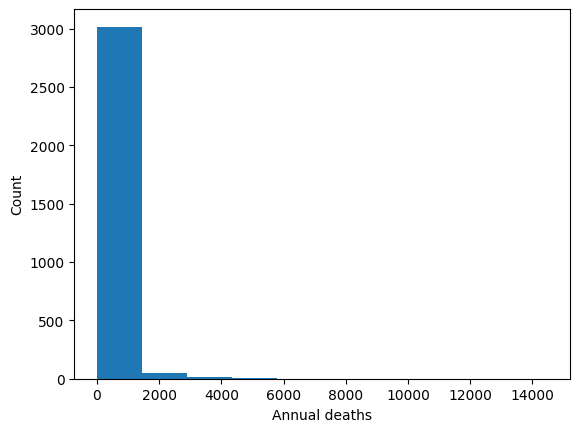

In [191]:
# your code here
plt.hist(rated["annual_deaths"].dropna())
plt.xlabel("Annual deaths")
plt.ylabel("Count")
plt.show()

In [192]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert abs(bowley(pd.Series([1, 2, 3, 10])) - 0.5) < 1e-9
assert abs(skew_table.loc["annual_deaths", "C"] - 11.621) < 0.001

## Question 21: Is n large enough?

> **Motivation.** A 95% $t$ interval for the mean of `death_rate`
> contains `mu` about 95% of the time. Does the same hold for the mean
> of `annual_deaths`?

Write a function **`t_coverage(column, n, reps)`** that takes the name
of a column of `rated`, a sample size and a number of samples. It draws
`reps` samples of `n` counties from `rated`, builds a 95% `t.interval`
for the mean of `column` from each, and returns the proportion of
intervals that contain the population mean of `column`.

Run the seed cell, then build and display a table with a row for each
$n$ of 10, 50 and 200 and a column for each of `death_rate` and
`annual_deaths`, from 1,000 samples each. To match your classmates’
numbers, build it in this order, all the `death_rate` values first:
`pd.DataFrame({"death_rate": [...], "annual_deaths": [...]}, index=[10, 50, 200])`.

*Hint: plenary 3.5’s slides “Why Skewness Matters: The Simulation” and
“Sample Size Rules of Thumb”.*

In [193]:
np.random.seed(306)

In [194]:
# your code here
def t_coverage(column, n, reps):
    population_mean = rated[column].mean()
    covered = []

    for _ in range(reps):
        sample = rated.sample(n=n)[column].dropna()

        sem = stats.sem(sample)
        lo, hi = stats.t.interval(
            confidence=0.95,
            df=len(sample) - 1,
            loc=sample.mean(),
            scale=sem
        )

        covered.append(lo <= population_mean <= hi)

    return np.mean(covered)

In [195]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert 0 <= t_coverage("death_rate", 10, 20) <= 1

## Question 22: Statistical and practical significance

> **Motivation.** With 50 counties the test of $H_0: \mu = 160$ did not
> reject. What happens with 1,000 counties, and does the answer matter?

A sample of 1,000 out of 3,084 counties is too large a share of the
population to treat the draws as independent, since $(N - n) / N$ is
about 0.68 (Module 2). Sampling **with replacement** makes the draws
independent. Run the seed cell, draw **`sample1000`**, 1,000 values of
`death_rate` from `rated` with `replace=True`. Display in one dictionary
`z_test(sample1000, 160)`, the 2-SEM `z_interval` of `sample1000`, the
difference between the sample mean and 160, and that difference as a
fraction of `sigma`, the spread of rates from county to county.

*Hint: plenary 3.5’s slide “Statistical vs. Practical Significance”.*

In [196]:
np.random.seed(307)

In [197]:
# your code here
sample1000 = rated["death_rate"].sample(n=1000, replace=True)

test_160 = z_test(sample1000, 160)
ci_1000 = z_interval(sample1000, 2)

difference = sample1000.mean() - 160
difference_fraction_sigma = difference / sigma

{
    "z test": test_160,
    "95% interval": ci_1000,
    "mean minus 160": difference,
    "difference as fraction of sigma": difference_fraction_sigma
}

{'z test': {'mean': np.float64(162.4706),
  'sem': np.float64(0.9613374981895936),
  'z': np.float64(2.5699611267142544),
  'p-value': np.float64(0.010170992738532236)},
 '95% interval': (np.float64(160.5479250036208),
  np.float64(164.39327499637918)),
 'mean minus 160': np.float64(2.4705999999999904),
 'difference as fraction of sigma': np.float64(0.08490508002431274)}

In [198]:
# Check your work. Delete the '# ' from the start of every line below
# these three, then run this cell. Every check should pass without printing anything.
# An AssertionError means that check found a bug.
assert len(sample1000) == 1000

# Printing your notebook

Printing from the browser often cuts off or drops plots. Use the “Run
All” option in the Runtime menu to make sure all of your cells work, and
check that they display what you expect before printing.

The first cell gets the printing tools. It takes about a minute, and you
only need to run it once each time you open the notebook.

In [199]:
!wget -q -N https://raw.githubusercontent.com/UM-Data-Science-101/data/main/Tools/print_notebook.py
from print_notebook import print_notebook, install_quarto
install_quarto()

'Quarto is installed. You can now print with print_notebook().'

The second cell prints. You can run it again whenever you change your
work. The PDF downloads as `notebook.pdf`.

In [201]:
# You can change either setting to False if you wish:
#   two_columns=False prints one wide column instead of two.
#   summary=False prints every cell in full, including the question text.
# Remove the # from the next line, then run this cell to print.
print_notebook(two_columns=False, summary=False)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>